# 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as norm
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

seed = 507

%matplotlib inline

In [ ]:
# You don't need to run code below since all_reviews_clean.parquet has already saved
data_path2 = "../data/all_reviews.parquet"

df = pd.read_parquet(data_path2)

In [ ]:
df.shape

(9901889, 19)

In [ ]:
# For visalization 1
df.head(5)

,rating,title,status,pros,cons,advice,Recommend,CEO Approval,Business Outlook,Career Opportunities,Compensation and Benefits,Senior Management,Work/Life Balance,Culture & Values,Diversity & Inclusion,firm_link,date,job,index
0,5.0,Good,"Current Employee, more than 10 years",Knowledge gain of complete project,Financial growth and personal growth,None,v,o,v,3.0,3.0,3.0,3.0,3.0,3.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Nov 19, 2022",Manager Design,NaN
1,4.0,Good,"Former Employee, less than 1 year","Good work,good work , flexible, support","Good,work, flexible,good support, good team work",None,v,o,o,4.0,4.0,4.0,4.0,4.0,4.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Jan 29, 2022",Anonymous Employee,NaN
2,4.0,"Supervising the manufacturing the processes, e...","Current Employee, more than 1 year",This company is a best opportunity for me to l...,"Monthly Target work,Maintain production schedu...",None,v,o,v,2.0,3.0,2.0,2.0,2.0,2.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Aug 12, 2021",Production Engineer,NaN
3,1.0,terrible,"Current Employee, more than 1 year",I wish there were some to list,too many to list here,None,x,x,x,1.0,3.0,1.0,3.0,1.0,NaN,https://www.glassdoor.com/Reviews/Calgary-Flam...,"Sep 24, 2020",Senior Account Executive,NaN
4,4.0,"It could be so good, but it isn’t","Current Employee, more than 3 years",Fast Paced. Endless challenges. Inclusive envi...,The biggest perk of the job provides no value ...,None,o,o,o,3.0,3.0,3.0,1.0,4.0,5.0,https://www.glassdoor.com/Reviews/Calgary-Flam...,"Mar 25, 2023",Assistant Manager,NaN


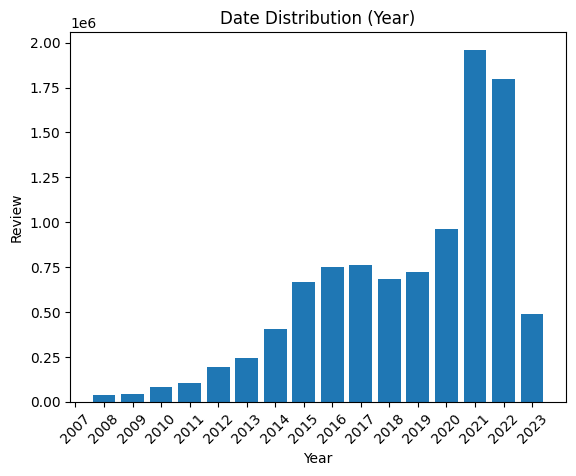

In [ ]:
# For visalization 2
copied_df = df.copy()
copied_df["date"] = pd.to_datetime(copied_df["date"])

plt.hist(copied_df["date"].dt.year, bins=np.arange(2007.5, 2024.5, 1), rwidth=0.8)
plt.title("Date Distribution (Year)")
plt.ylabel("Review")
plt.xlabel("Year")
plt.xticks(range(2007, 2024), rotation=45)

plt.show()

In [ ]:
# For visalization 3
status = copied_df["status"].str.strip()
copied_df["emp_type"] = status.str.extract(r"^(?:Current|Former) ([^,]+)")[0]

print(copied_df["emp_type"].unique())
print(f"Employee: {(len(copied_df[copied_df["emp_type"] == 'Employee']) / len(copied_df["emp_type"])) * 100} %")

['Employee' 'Contractor' 'Temporary Employee' 'Intern' 'Freelancer' nan
 'Apprentice' 'Trainee' 'PhD']
Employee: 99.89916065510329 %


# 1. Data Cleaning

In [ ]:
columns = ["title", "rating", "status", "pros", "cons", "firm_link", "date", "job"]
df = df[columns]

In [ ]:
df.head(1)

,title,rating,status,pros,cons,firm_link,date,job
0,Good,5.0,"Current Employee, more than 10 years",Knowledge gain of complete project,Financial growth and personal growth,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Nov 19, 2022",Manager Design


In [ ]:
df["firm_id"] = df["firm_link"].str.extract(r"-Reviews-E(\d+)")[0]
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())
print(df["number of reviews"].describe())
print(f"Number of firms: {df['firm_id'].nunique()}")
print(f"Missing firm_id: {df['firm_id'].isna().sum()}")

count    9.901889e+06
mean     1.423114e+04
std      2.547091e+04
min      1.000000e+00
25%      1.275000e+03
50%      4.390000e+03
75%      1.353400e+04
max      1.584920e+05
Name: number of reviews, dtype: float64
Number of firms: 35311
Missing firm_id: 0


In [ ]:
# Drop duplicates
key = ["title", "rating", "status", "pros", "cons", "firm_id", "date", "job"]
n_before = len(df)
df = df.drop_duplicates(subset=key)
print(f"Before: {n_before}\nAfter: {len(df)}")

Before: 9901889
After: 9466241


In [ ]:
# Create new columns from status, date, and rating
df = df.drop(columns="pros")

status = df["status"].str.strip()
df["former"] = status.str.extract(r"^(Current|Former) ")[0].map({"Current": 0, "Former": 1})
df["emp_type"] = status.str.extract(r"^(?:Current|Former) ([^,]+)")[0]
df["tenure"] = status.str.extract(r"(less than 1 year|more than \d+ years?)")[0]
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

In [ ]:
# Drop invalid rows
n_before = len(df)
df = df.dropna(subset=["firm_id", "rating", "former", "date"])
print(f"Before: {n_before:,}\nAfter: {len(df):,}")

df = df.astype({"firm_id": "int64", "rating": "int8", "former": "int8", "year": "int16"})
df["emp_type"] = df["emp_type"].astype("category")
df["tenure"] = df["tenure"].astype("category")
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())

print(df["rating"].value_counts().sort_index())
print(df["former"].value_counts())
print(df["emp_type"].value_counts().head(10))

Before: 9,466,241
After: 9,465,873
rating
1     891219
2     983161
3    2193082
4    2826220
5    2572191
Name: count, dtype: int64
former
0    5457688
1    4008185
Name: count, dtype: int64
emp_type
Employee              9456305
Intern                   4246
Contractor               3957
Freelancer                887
Temporary Employee        470
Apprentice                  6
PhD                         1
Trainee                     1
Name: count, dtype: int64


In [ ]:
# Save
clean_path = data_path2.replace("all_reviews.parquet", "all_reviews_clean.parquet")
cols = ["firm_id", "rating", "former", "emp_type", "tenure", "year", "date", "number of reviews", "cons", "job"]
df[cols].to_parquet(clean_path, index=False)

# 2. Sample Analysis

In [ ]:
data_path3 = "../data/all_reviews_clean.parquet"

df = pd.read_parquet(data_path3)

In [4]:
# Targets are only employees
# And use reviews since 2020
n_before = len(df)
df = df[(df["emp_type"] == "Employee") & (df["year"] >= 2020)]
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())
print(f"Before: {n_before:,}\nAfter: {len(df):,}")

Before: 9,465,873
After: 4,950,344


In [5]:
print(df.columns)

Index(['firm_id', 'rating', 'former', 'emp_type', 'tenure', 'year', 'date',
       'number of reviews', 'cons', 'job'],
      dtype='object')


In [6]:
means = df.groupby("former")["rating"].mean()
print(means[1] - means[0])

-0.4999101794668488


In [7]:
counts = df.groupby(["firm_id", "former"]).size().unstack()
large = counts[(counts[0] >= 5000) & (counts[1] >= 1000)]
len(large)

60

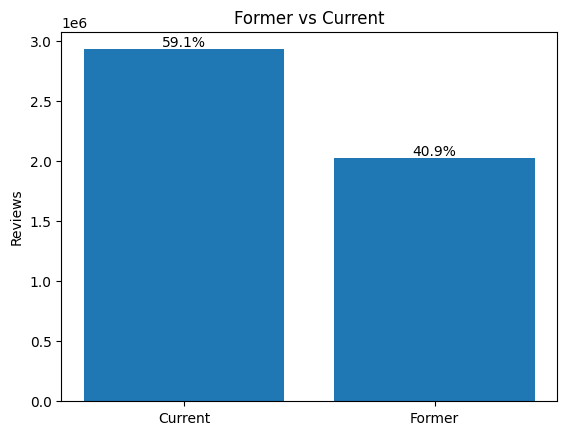

In [8]:
counts = df["former"].map({1: "Former", 0: "Current"}).value_counts()
pct = counts / counts.sum() * 100

bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars, labels=[f"{p:.1f}%" for p in pct])
plt.title("Former vs Current")
plt.ylabel("Reviews")
plt.show()

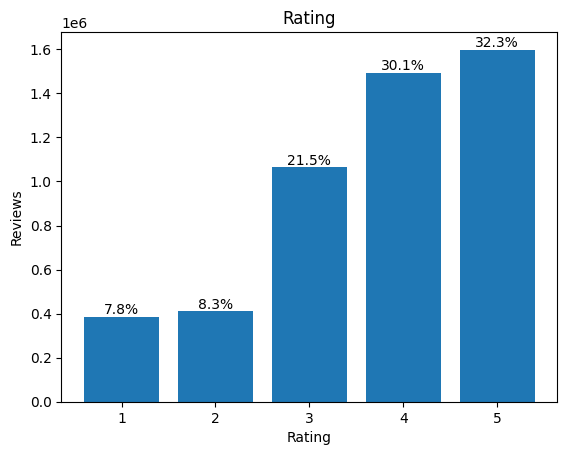

In [9]:
counts = df["rating"].value_counts().sort_index()
pct = counts / counts.sum() * 100

bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars, labels=[f"{p:.1f}%" for p in pct])
plt.title("Rating")
plt.xlabel("Rating")
plt.ylabel("Reviews")
plt.show()

In [10]:
print(f"Mean: {df["rating"].mean()} \nMedian: {df["rating"].median()}")

Mean: 3.708372589864462 
Median: 4.0


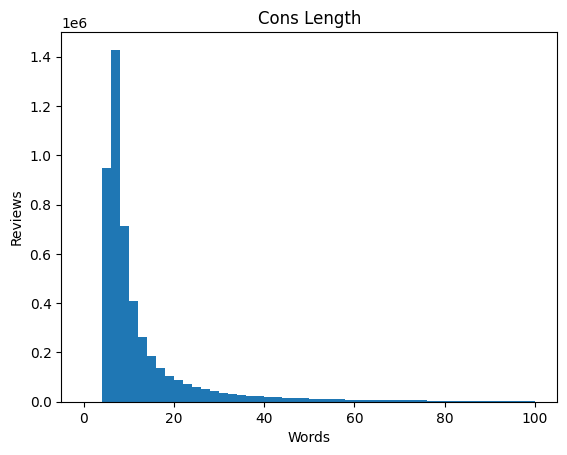

In [11]:
cons_len = df["cons"].str.split().str.len()

plt.hist(cons_len, bins=50, range=(0, 100))
plt.title("Cons Length")
plt.xlabel("Words")
plt.ylabel("Reviews")
plt.show()

In [12]:
print(f"Mean: {cons_len.mean()} \nMedian: {cons_len.median()}")

Mean: 15.276002693146717 
Median: 8.0


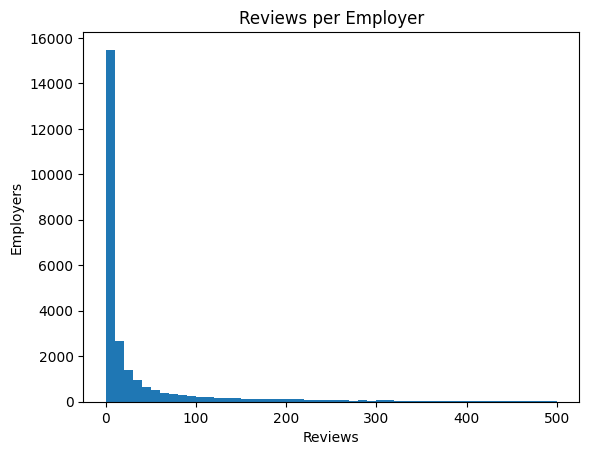

In [13]:
per_firm = df["firm_id"].value_counts()

plt.hist(per_firm, bins=50, range=(0, 500))
plt.title("Reviews per Employer")
plt.xlabel("Reviews")
plt.ylabel("Employers")
plt.show()

In [14]:
print(f"Mean: {per_firm.mean()} \nMedian: {per_firm.median()}")

Mean: 178.53231390652047 
Median: 7.0


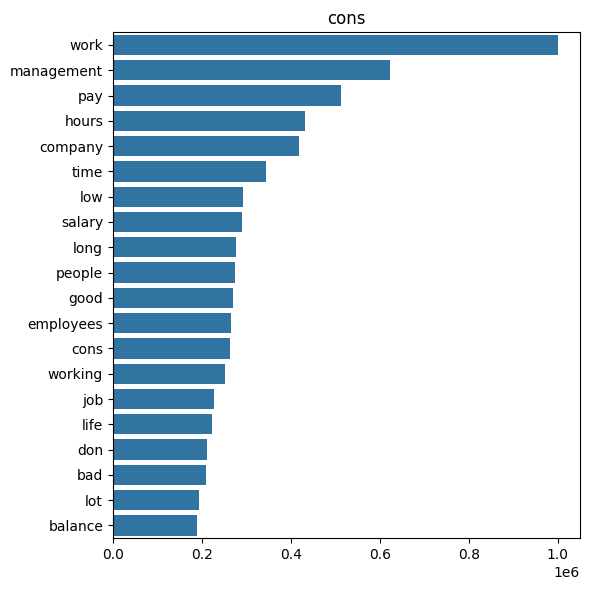

In [15]:
def top_words(series, n=20):
    counter = Counter()
    for tokens in series.dropna().str.lower().str.findall(r"[a-z]+"):
        counter.update(w for w in tokens if len(w) > 1 and w not in ENGLISH_STOP_WORDS)
    return counter.most_common(n)

words, counts = zip(*top_words(df["cons"]))

plt.figure(figsize=(6, 6))
sns.barplot(x=list(counts), y=list(words))
plt.title("cons")
plt.tight_layout()
plt.show()

In [16]:
sd = df["rating"].std()
n_star = int(np.ceil(2 * (1.96 * sd / 0.25) ** 2))

counts = df.groupby(["firm_id", "former"]).size().unstack(fill_value=0)
enough = counts.min(axis=1) >= n_star

print(f"SD: {sd:.2f}")
print(f"n* per group: {n_star}")
print(f"Employers without enough reviews: {(~enough).mean():.1%}")
print(f"Reviews covered: {counts[enough].sum().sum() / counts.sum().sum():.1%}")

SD: 1.22
n* per group: 183
Employers without enough reviews: 93.3%
Reviews covered: 80.1%


In [17]:
# Decide the number of minimum reviews
counts = df.groupby("firm_id")["former"].agg(n_former="sum", n_total="size")
counts["n_current"] = counts["n_total"] - counts["n_former"]
for k in [10, 30, 100]:
    ok = (counts["n_former"] >= k) & (counts["n_current"] >= k)
    print(f"k={k}: firms={ok.sum():,} reviews={counts.loc[ok, 'n_total'].sum():,}")

k=10: firms=8,539 reviews=4,842,081
k=30: firms=5,450 reviews=4,698,151
k=100: firms=2,780 reviews=4,300,780


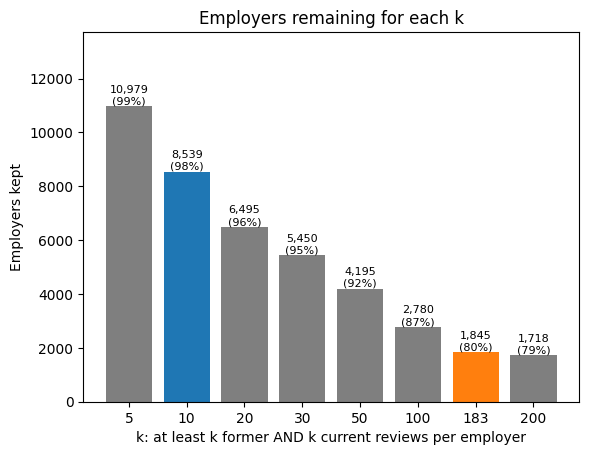

In [19]:
counts["n_min"] = counts[["n_former", "n_current"]].min(axis=1)
ks = [5, 10, 20, 30, 50, 100, 183, 200]
firms_kept = [(counts["n_min"] >= k).sum() for k in ks]
reviews_kept = [counts.loc[counts["n_min"] >= k, "n_total"].sum() / counts["n_total"].sum() * 100 for k in ks]

highlight = {10: "tab:blue", 183: "tab:orange"}
colors = [highlight.get(k, "tab:gray") for k in ks]

plt.bar([str(k) for k in ks], firms_kept, color=colors)
for i, (f, r) in enumerate(zip(firms_kept, reviews_kept)):
    plt.text(i, f, f"{f:,}\n({r:.0f}%)", ha="center", va="bottom", fontsize=8)
plt.ylim(0, max(firms_kept) * 1.25)
plt.xlabel("k: at least k former AND k current reviews per employer")
plt.ylabel("Employers kept")
plt.title("Employers remaining for each k")
plt.show()

# Employer Split

In [ ]:
# Set the number of minimum reviews to 20
k = 20
keep = counts.index[(counts["n_former"] >= k) & (counts["n_current"] >= k)]
df = df[df["firm_id"].isin(keep)]

rng = np.random.default_rng(seed)
firms = df["firm_id"].unique()
test_firms = rng.choice(firms, size=int(len(firms) * 0.2), replace=False)
df["split"] = np.where(df["firm_id"].isin(test_firms), "test", "train")

print(df.groupby("split").agg(firms=("firm_id", "nunique"), reviews=("firm_id", "size"), former_share=("former", "mean")))
pd.Series(test_firms, name="firm_id").to_csv(clean_path.replace(".parquet", "_test_firms.csv"), index=False)

       firms  reviews  former_share
split                              
test    1299   944190      0.399384
train   5196  3821216      0.407739


# Exploration for Hypothesis
## 4a. RQ1:
Within the same company, how differently do former and current employees rate their employer?


## 4b. RQ2:
Within the same company and at the same rating, does review text still distinguish former from current employees, and what words or themes drive that distinction?

## 4c, RQ3:
To trust a rating gap between current and former employees, how many reviews are necessary?